In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [7]:
data = pd.read_csv("C:/Users/DELL/OneDrive/Documents/drive-download-20261027T110517Z-1-001/50_Startups.csv")

data.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [8]:
data.shape

(50, 5)

In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     str    
 4   Profit           50 non-null     float64
dtypes: float64(4), str(1)
memory usage: 2.5 KB


In [10]:
data.describe()

,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


In [11]:
data.isnull().sum()


R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64

In [12]:
data.duplicated().sum()

np.int64(0)

In [14]:
data = data.drop_duplicates()

In [15]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     str    
 4   Profit           50 non-null     float64
dtypes: float64(4), str(1)
memory usage: 2.5 KB


In [17]:
data.shape

(50, 5)

In [18]:
business_questions = [
    "Which state generates the highest average profit?",
    "Which expenditure has the strongest relationship with profit?",
    "What is the average profit of startups?",
    "Which startup has the highest profit?",
    "How does R&D spending relate to profit?"
]

for j, question in enumerate(business_questions, start=1):
    print(f"Q{j}. {question}")

Q1. Which state generates the highest average profit?
Q2. Which expenditure has the strongest relationship with profit?
Q3. What is the average profit of startups?
Q4. Which startup has the highest profit?
Q5. How does R&D spending relate to profit?


In [19]:
state_profit = data.groupby("State")["Profit"].mean()

state_profit

State
California    103905.175294
Florida       118774.024375
New York      113756.446471
Name: Profit, dtype: float64

In [20]:
state_profit = data.groupby("State")["Profit"].mean()

state_profit

State
California    103905.175294
Florida       118774.024375
New York      113756.446471
Name: Profit, dtype: float64

In [21]:
state_profit.sort_values(ascending=False)

State
Florida       118774.024375
New York      113756.446471
California    103905.175294
Name: Profit, dtype: float64

In [22]:
highest_state = state_profit.idxmax()

highest_profit = state_profit.max()

print("Highest Average Profit State:", highest_state)
print("Average Profit:", highest_profit)


Highest Average Profit State: Florida
Average Profit: 118774.02437500001


In [23]:
correlation = data[
    ["R&D Spend", "Administration", "Marketing Spend", "Profit"]
].corr()

correlation

,R&D Spend,Administration,Marketing Spend,Profit
R&D Spend,1.000000,0.241955,0.724248,0.972900
Administration,0.241955,1.000000,-0.032154,0.200717
Marketing Spend,0.724248,-0.032154,1.000000,0.747766
Profit,0.972900,0.200717,0.747766,1.000000


In [24]:
profit_correlation = correlation["Profit"].drop("Profit")

profit_correlation

R&D Spend          0.972900
Administration     0.200717
Marketing Spend    0.747766
Name: Profit, dtype: float64

In [25]:
strongest_expense = profit_correlation.abs().idxmax()

strongest_value = profit_correlation[strongest_expense]

print("Strongest Expenditure:", strongest_expense)
print("Correlation with Profit:", strongest_value)


Strongest Expenditure: R&D Spend
Correlation with Profit: 0.9729004656594831


In [27]:
average_profit = data["Profit"].mean()

print("Average Startup Profit:", average_profit)

Average Startup Profit: 112012.63920000002


In [28]:
highest_profit_index = data["Profit"].idxmax()

highest_profit_startup = data.loc[highest_profit_index]

highest_profit_startup

R&D Spend           165349.2
Administration      136897.8
Marketing Spend     471784.1
State               New York
Profit             192261.83
Name: 0, dtype: object

In [29]:
rd_profit_correlation = data["R&D Spend"].corr(data["Profit"])

print("R&D Spend and Profit Correlation:", rd_profit_correlation)

R&D Spend and Profit Correlation: 0.9729004656594832


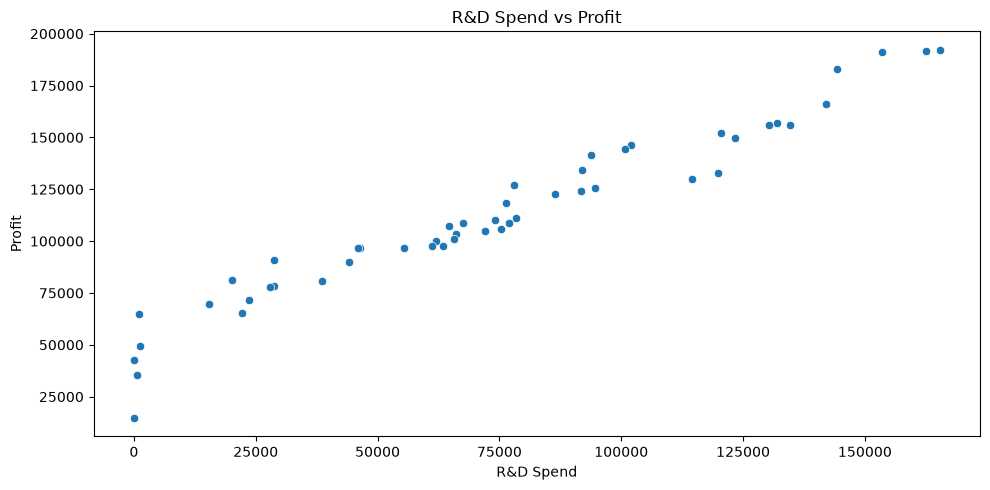

In [30]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=data, x="R&D Spend", y="Profit")

plt.title("R&D Spend vs Profit")
plt.xlabel("R&D Spend")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

In [31]:
state_profit = data.groupby("State")["Profit"].mean()

state_profit = state_profit.sort_values(ascending=False)

print(state_profit)

State
Florida       118774.024375
New York      113756.446471
California    103905.175294
Name: Profit, dtype: float64


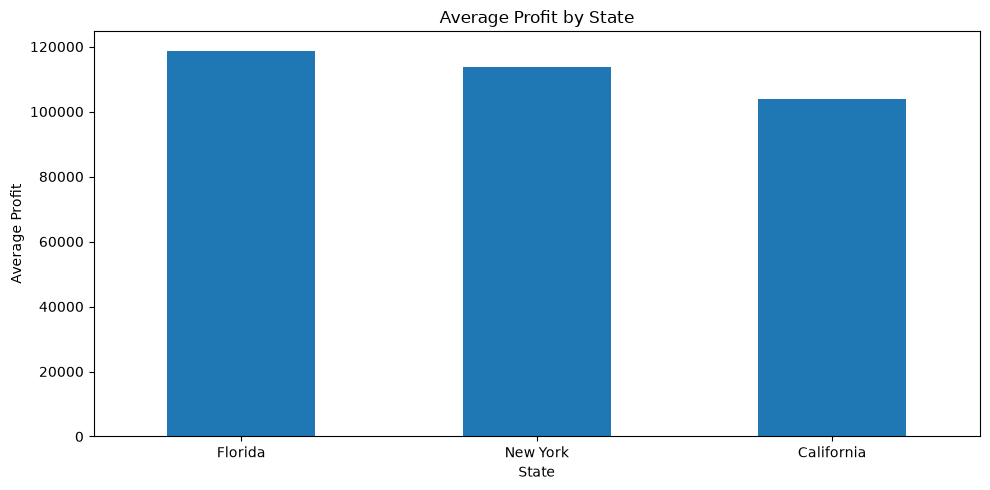

In [32]:
state_profit.plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Profit by State"
)

plt.xlabel("State")
plt.ylabel("Average Profit")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [33]:
correlation = data[
    ["R&D Spend", "Administration", "Marketing Spend", "Profit"]
].corr()

print(correlation)

                 R&D Spend  Administration  Marketing Spend    Profit
R&D Spend         1.000000        0.241955         0.724248  0.972900
Administration    0.241955        1.000000        -0.032154  0.200717
Marketing Spend   0.724248       -0.032154         1.000000  0.747766
Profit            0.972900        0.200717         0.747766  1.000000


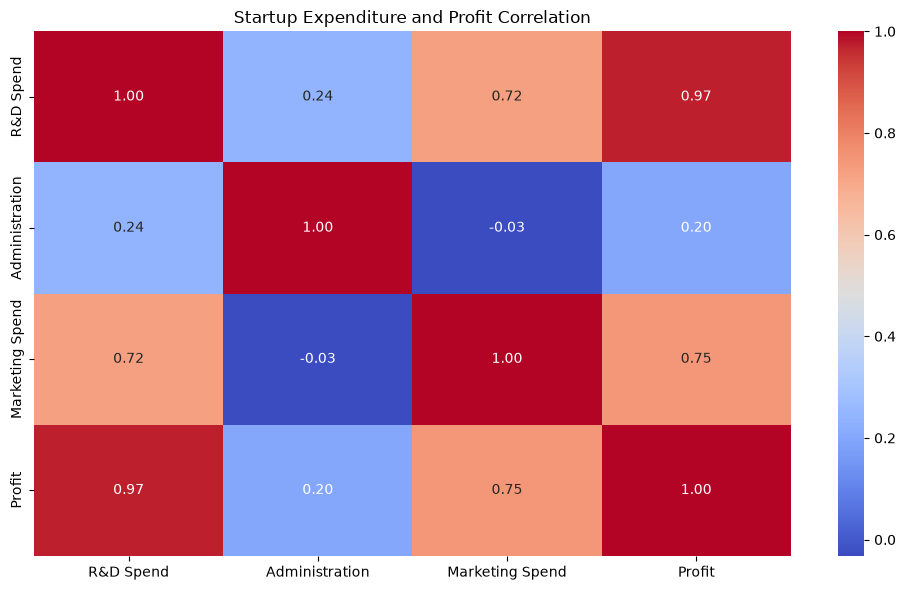

In [34]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Startup Expenditure and Profit Correlation")
plt.tight_layout()
plt.show()

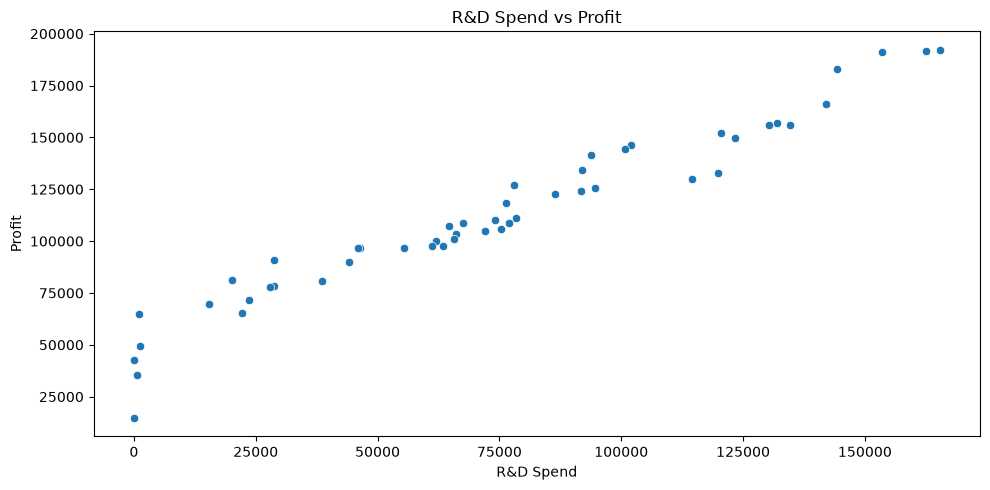

In [37]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=data,
    x="R&D Spend",
    y="Profit"
)

plt.title("R&D Spend vs Profit")
plt.xlabel("R&D Spend")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

In [38]:
expense_profit = data[
    ["R&D Spend", "Administration", "Marketing Spend", "Profit"]
].corr()["Profit"].drop("Profit")

print(expense_profit)

R&D Spend          0.972900
Administration     0.200717
Marketing Spend    0.747766
Name: Profit, dtype: float64


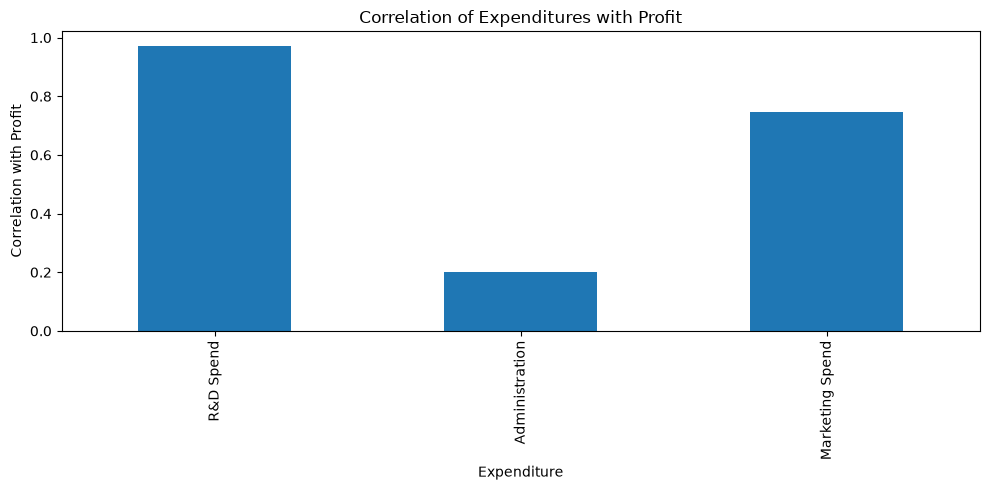

In [39]:
expense_profit.plot(
    kind="bar",
    figsize=(10, 5),
    title="Correlation of Expenditures with Profit"
)

plt.xlabel("Expenditure")
plt.ylabel("Correlation with Profit")

plt.tight_layout()
plt.show()

In [40]:
import sqlite3
import pandas as pd

connection = sqlite3.connect("startup_analysis.db")

print("Connected to SQLite Database Successfully!")

Connected to SQLite Database Successfully!


In [42]:
%pip install mysql-connector-python

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/18.2 MB ? eta -:--:--
   - -------------------------------------- 0.8/18.2 MB 5.4 MB/s eta 0:00:04
   --- ------------------------------------ 1.6/18.2 MB 4.7 MB/s eta 0:00:04
   ----- ---------------------------------- 2.4/18.2 MB 4.2 MB/s eta 0:00:04
   ------- -------------------------------- 3.4/18.2 MB 4.3 MB/s eta 0:00:04
   -------- ------------------------------- 3.9/18.2 MB 3.8 MB/s eta 0:00:04
   --------- ------------------------------ 4.5/18.2 MB 3.6 MB/s eta 0:00:04
   ---------- ----------------------------- 5.0/18.2 MB 3.5 MB/s eta 0:00:04
   ------------ --------------------------- 5.5/18.2 MB 3.3 MB/s eta 0:00:04
   ------------- -------------------------- 6.0/18.2 MB 3.3 MB/s eta 0:00:04
   -------------- ------------------------- 6.8/18.2 MB 3.3 MB/s eta 0:00:04
   ---------------- ----------------------- 7.6/18.2 MB 3.3 MB/s eta 0:00:04
   --


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
import mysql.connector
import pandas as pd

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [44]:
connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="",
    database="startup_analysis",
    port=3306
)

print("MySQL Connected Successfully!")

MySQL Connected Successfully!


In [46]:
print("MySQL Connection:", connection.is_connected())

print("Dataset Shape:", data.shape)

print("Dataset Columns:", data.columns.tolist())

MySQL Connection: True
Dataset Shape: (50, 5)
Dataset Columns: ['R&D Spend', 'Administration', 'Marketing Spend', 'State', 'Profit']


In [47]:
cursor = connection.cursor()

create_table_query = """
CREATE TABLE IF NOT EXISTS startups (
    `R&D Spend` DOUBLE,
    Administration DOUBLE,
    `Marketing Spend` DOUBLE,
    State VARCHAR(50),
    Profit DOUBLE
)
"""

cursor.execute(create_table_query)

print("Startups Table Created Successfully!")

Startups Table Created Successfully!


In [48]:
cursor.execute("SHOW TABLES")

for table in cursor.fetchall():
    print(table)
    

('startups',)


In [49]:
insert_query = """
INSERT INTO startups
(`R&D Spend`, Administration, `Marketing Spend`, State, Profit)
VALUES (%s, %s, %s, %s, %s)
"""

records = [
    tuple(row)
    for row in data.itertuples(index=False, name=None)
]

cursor.executemany(insert_query, records)

connection.commit()

print(cursor.rowcount, "Records Inserted Successfully!")

50 Records Inserted Successfully!


In [50]:
cursor.execute("SELECT COUNT(*) FROM startups")

total_records = cursor.fetchone()[0]

print("Total Records in MySQL:", total_records)

Total Records in MySQL: 50


In [51]:
query = """
SELECT *
FROM startups
LIMIT 5
"""

result = pd.read_sql_query(query, connection)

print(result)

   R&D Spend  Administration  Marketing Spend       State     Profit
0  165349.20       136897.80        471784.10    New York  192261.83
1  162597.70       151377.59        443898.53  California  191792.06
2  153441.51       101145.55        407934.54     Florida  191050.39
3  144372.41       118671.85        383199.62    New York  182901.99
4  142107.34        91391.77        366168.42     Florida  166187.94


C:\Users\DELL\AppData\Local\Temp\ipykernel_10636\1907259061.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(query, connection)


In [52]:
cursor.execute("DESCRIBE startups")

for column in cursor.fetchall():
    print(column)

('R&D Spend', 'double', 'YES', '', None, '')
('Administration', 'double', 'YES', '', None, '')
('Marketing Spend', 'double', 'YES', '', None, '')
('State', 'varchar(50)', 'YES', '', None, '')
('Profit', 'double', 'YES', '', None, '')


In [53]:
query1 = """
SELECT
    State,
    AVG(Profit) AS Average_Profit
FROM startups
GROUP BY State
ORDER BY Average_Profit DESC
"""

result1 = pd.read_sql_query(query1, connection)

print(result1)

        State  Average_Profit
0     Florida   118774.024375
1    New York   113756.446471
2  California   103905.175294


C:\Users\DELL\AppData\Local\Temp\ipykernel_10636\1549966737.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result1 = pd.read_sql_query(query1, connection)


In [54]:
query2 = """
SELECT
    AVG(`R&D Spend`) AS Average_RD_Spend,
    AVG(Administration) AS Average_Administration,
    AVG(`Marketing Spend`) AS Average_Marketing_Spend,
    AVG(Profit) AS Average_Profit
FROM startups
"""

result2 = pd.read_sql_query(query2, connection)

print(result2)

   Average_RD_Spend  Average_Administration  Average_Marketing_Spend  \
0        73721.6156             121344.6396              211025.0978   

   Average_Profit  
0     112012.6392  


C:\Users\DELL\AppData\Local\Temp\ipykernel_10636\1368838859.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result2 = pd.read_sql_query(query2, connection)


In [55]:
query3 = """
SELECT
    AVG(Profit) AS Average_Profit
FROM startups
"""

result3 = pd.read_sql_query(query3, connection)

print(result3)

   Average_Profit
0     112012.6392


C:\Users\DELL\AppData\Local\Temp\ipykernel_10636\1027065162.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result3 = pd.read_sql_query(query3, connection)


In [56]:
query4 = """
SELECT *
FROM startups
ORDER BY Profit DESC
LIMIT 1
"""

result4 = pd.read_sql_query(query4, connection)

print(result4)

   R&D Spend  Administration  Marketing Spend     State     Profit
0   165349.2        136897.8         471784.1  New York  192261.83


C:\Users\DELL\AppData\Local\Temp\ipykernel_10636\2261829598.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result4 = pd.read_sql_query(query4, connection)


In [57]:
query4 = """
SELECT *
FROM startups
ORDER BY Profit DESC
LIMIT 1
"""

result4 = pd.read_sql_query(query4, connection)

print(result4)

   R&D Spend  Administration  Marketing Spend     State     Profit
0   165349.2        136897.8         471784.1  New York  192261.83


C:\Users\DELL\AppData\Local\Temp\ipykernel_10636\2261829598.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result4 = pd.read_sql_query(query4, connection)


In [58]:
query4 = """
SELECT *
FROM startups
ORDER BY Profit DESC
LIMIT 1
"""

result4 = pd.read_sql_query(query4, connection)

print(result4)

   R&D Spend  Administration  Marketing Spend     State     Profit
0   165349.2        136897.8         471784.1  New York  192261.83


C:\Users\DELL\AppData\Local\Temp\ipykernel_10636\2261829598.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result4 = pd.read_sql_query(query4, connection)


In [59]:
cursor.close()
connection.close()

print("MySQL Connection Closed Successfully!")

MySQL Connection Closed Successfully!
